# Tác động của AI đến Việc làm năm 2030
### Notebook 1/2 — Khám phá dữ liệu thô & Tiền xử lý (EDA + Data Cleaning)

**Học phần:** Phân tích Kinh doanh — Học viện Ngân hàng
**Sinh viên thực hiện:** Đỗ Văn Đạt
**Đề tài (Bài tập cuối kỳ):** Tác động của Trí tuệ nhân tạo (AI) đến rủi ro tự động hoá việc làm năm 2030
**Bộ dữ liệu:** `AI_ViecLam2030_Raw.csv` — 3.000 quan sát x 18 biến, tổng hợp đặc điểm 20 nghề nghiệp
(lương, kinh nghiệm, học vấn, các chỉ số phơi nhiễm AI, 10 nhóm điểm kỹ năng, xác suất & nhóm
rủi ro tự động hoá năm 2030).

**Phong cách trình bày notebook** (đọc dữ liệu → hiển thị dòng đầu → EDA từng bước có nhận xét)
tham khảo từ notebook Kaggle: *Predicting Uber Ride Cancellations* —
https://www.kaggle.com/code/denvermagtibay/predicting-uber-ride-cancellations

**Mục tiêu notebook này:**
1. Đọc và khám phá cấu trúc dữ liệu thô.
2. Kiểm tra & xử lý dữ liệu thiếu, trùng lặp, ngoài miền giá trị hợp lệ, ngoại lai.
3. Phát hiện và ghi nhận rủi ro rò rỉ dữ liệu (data leakage) giữa các biến.
4. Tạo các biến đặc trưng mới (feature engineering) phục vụ mô hình hoá ở Notebook 2.
5. Phân tích khám phá dữ liệu (EDA) bằng 8 biểu đồ trực quan, mỗi biểu đồ kèm một câu nhận xét.

## 0. Nạp thư viện

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

HVNH_NAVY = "#1F3864"
HVNH_ORANGE = "#ED7D31"
HVNH_BLUE = "#2E5496"
PALETTE_RISK = {"Low": "#2E7D32", "Medium": "#ED7D31", "High": "#C0392B"}
RISK_ORDER = ["Low", "Medium", "High"]
SKILL_COLS = [f"Skill_{i}" for i in range(1, 11)]

sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["font.family"] = "DejaVu Sans"

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
print("Thư viện đã sẵn sàng.")

Thư viện đã sẵn sàng.


## 1. Đọc & khám phá dữ liệu thô (Load and show first rows)

Bước đầu tiên: đọc file CSV gốc, xem kích thước, 5 dòng đầu và kiểu dữ liệu của từng cột —
tương tự bước "Load and Show First Rows" trong notebook tham khảo Kaggle.

In [2]:
df_raw = pd.read_csv("AI_ViecLam2030_Raw.csv")
print("Kích thước dữ liệu thô:", df_raw.shape)
df_raw.head()

Kích thước dữ liệu thô: (3000, 18)


,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,Skill_3,Skill_4,Skill_5,Skill_6,Skill_7,Skill_8,Skill_9,Skill_10
0,Security Guard,45795,28,Master's,0.18,1.28,0.85,High,0.45,0.10,0.46,0.33,0.14,0.65,0.06,0.72,0.94,0.00
1,Research Scientist,133355,20,PhD,0.62,1.11,0.05,Low,0.02,0.52,0.40,0.05,0.97,0.23,0.09,0.62,0.38,0.98
2,Construction Worker,146216,2,High School,0.86,1.18,0.81,High,0.01,0.94,0.56,0.39,0.02,0.23,0.24,0.68,0.61,0.83
3,Software Engineer,136530,13,PhD,0.39,0.68,0.60,Medium,0.43,0.21,0.57,0.03,0.84,0.45,0.40,0.93,0.73,0.33
4,Financial Analyst,70397,22,High School,0.52,1.46,0.64,Medium,0.75,0.54,0.59,0.97,0.61,0.28,0.30,0.17,0.02,0.42


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Job_Title                    3000 non-null   str    
 1   Average_Salary               3000 non-null   int64  
 2   Years_Experience             3000 non-null   int64  
 3   Education_Level              3000 non-null   str    
 4   AI_Exposure_Index            3000 non-null   float64
 5   Tech_Growth_Factor           3000 non-null   float64
 6   Automation_Probability_2030  3000 non-null   float64
 7   Risk_Category                3000 non-null   str    
 8   Skill_1                      3000 non-null   float64
 9   Skill_2                      3000 non-null   float64
 10  Skill_3                      3000 non-null   float64
 11  Skill_4                      3000 non-null   float64
 12  Skill_5                      3000 non-null   float64
 13  Skill_6                      

In [4]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Average_Salary,3000.0,89372.279000,34608.088767,30030.00,58640.00,89318.000,119086.50,149798.00
Years_Experience,3000.0,14.677667,8.739788,0.00,7.00,15.000,22.00,29.00
AI_Exposure_Index,3000.0,0.501283,0.284004,0.00,0.26,0.500,0.74,1.00
Tech_Growth_Factor,3000.0,0.995343,0.287669,0.50,0.74,1.000,1.24,1.50
Automation_Probability_2030,3000.0,0.501503,0.247881,0.05,0.31,0.500,0.70,0.95
Skill_1,3000.0,0.496973,0.287888,0.00,0.24,0.505,0.74,1.00
Skill_2,3000.0,0.497233,0.288085,0.00,0.25,0.500,0.74,1.00
Skill_3,3000.0,0.499313,0.288354,0.00,0.25,0.500,0.75,1.00
Skill_4,3000.0,0.503667,0.287063,0.00,0.26,0.510,0.75,1.00
Skill_5,3000.0,0.490270,0.285818,0.00,0.24,0.490,0.73,1.00


**Nhận xét:** Dữ liệu thô có 3.000 dòng, 18 cột, gồm 1 biến định danh nghề nghiệp (`Job_Title`,
20 giá trị), 1 biến định tính thứ bậc (`Education_Level`), 1 biến mục tiêu phân loại
(`Risk_Category`), và 15 biến định lượng — trong đó 12 biến (AI_Exposure_Index,
Automation_Probability_2030, Skill_1..10) bị giới hạn trong đoạn [0, 1].

## 2. Tiền xử lý dữ liệu

### 2.1. Dữ liệu thiếu

In [5]:
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)
report = pd.DataFrame({"So_o_thieu": missing, "Ty_le_%": missing_pct})
report[report["So_o_thieu"] > 0] if missing.sum() > 0 else print("Không có ô nào bị thiếu dữ liệu.")

Không có ô nào bị thiếu dữ liệu.


**Nhận xét:** Bộ dữ liệu không có ô nào bị thiếu — phù hợp với một bộ dữ liệu mô phỏng (synthetic) được sinh có kiểm soát, khác với dữ liệu thu thập thực tế thường có tỷ lệ thiếu nhất định.

### 2.2. Dữ liệu trùng lặp

In [6]:
n_dup = int(df_raw.duplicated().sum())
df = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Số dòng trùng lặp phát hiện & loại bỏ: {n_dup}")
print(f"Số dòng còn lại: {len(df)}")

Số dòng trùng lặp phát hiện & loại bỏ: 0
Số dòng còn lại: 3000


### 2.3. Kiểm tra miền giá trị hợp lệ (business rule validation)

Các chỉ số `AI_Exposure_Index`, `Automation_Probability_2030` và 10 biến `Skill_1..10` về bản chất là các thang đo chuẩn hoá trong đoạn [0, 1]. Dòng nào vi phạm được xem là lỗi nhập liệu/mô phỏng và bị loại.

In [7]:
bounded_0_1 = ["AI_Exposure_Index", "Automation_Probability_2030"] + SKILL_COLS
invalid_rows = pd.Series(False, index=df.index)
for col in bounded_0_1:
    invalid_rows |= ~df[col].between(0, 1)
n_invalid = int(invalid_rows.sum())
df = df.loc[~invalid_rows].reset_index(drop=True)
print(f"Số dòng vi phạm miền giá trị [0,1]: {n_invalid}")
print(f"Số dòng còn lại sau bước làm sạch: {len(df)}")

Số dòng vi phạm miền giá trị [0,1]: 0
Số dòng còn lại sau bước làm sạch: 3000


### 2.4. Ngoại lai (quy tắc IQR) trên `Average_Salary`

In [8]:
q1, q3 = df["Average_Salary"].quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_outliers_salary = int(((df["Average_Salary"] < lower) | (df["Average_Salary"] > upper)).sum())
print(f"Q1={q1:.0f}  Q3={q3:.0f}  IQR={iqr:.0f}")
print(f"Cận dưới={lower:.0f}  Cận trên={upper:.0f}")
print(f"Số hồ sơ ngoại lai theo IQR: {n_outliers_salary}")

Q1=58640  Q3=119086  IQR=60446
Cận dưới=-32030  Cận trên=209756
Số hồ sơ ngoại lai theo IQR: 0


**Nhận xét:** Không có hồ sơ nào vượt ngưỡng IQR — mức lương trong dữ liệu trải khá đều từ thấp đến cao mà không có giá trị cực đoan bất thường, nên **không cần loại bỏ** dòng nào ở bước này.

### 2.5. Kiểm tra rò rỉ dữ liệu (data leakage) — phát hiện quan trọng nhất

Trước khi mô hình hoá, cần kiểm tra: `Risk_Category` có thực sự là một biến độc lập, hay chỉ là
biến **phái sinh (rule-based)** từ `Automation_Probability_2030`? Nếu là biến phái sinh, đưa
`Automation_Probability_2030` vào tập đặc trưng khi dự báo `Risk_Category` sẽ gây rò rỉ dữ liệu
(mô hình "ăn gian" vì biết trước gần như chính xác câu trả lời).

In [9]:
risk_bins = df.groupby("Risk_Category")["Automation_Probability_2030"].agg(["min", "max", "count"])
risk_bins

,min,max,count
Risk_Category,,,
High,0.71,0.95,740
Low,0.05,0.30,739
Medium,0.31,0.70,1521


**Nhận xét:** Ba nhóm rủi ro tương ứng CHÍNH XÁC với 3 khoảng giá trị rời rạc của `Automation_Probability_2030` (Low: 0.05–0.30, Medium: 0.31–0.70, High: 0.71–0.95) — không có điểm chồng lấn. Điều này xác nhận `Risk_Category` là biến phái sinh theo ngưỡng cố định. **Quyết định phương pháp luận:** ở Notebook 2, `Automation_Probability_2030` sẽ bị loại khỏi tập đặc trưng khi huấn luyện mô hình phân loại `Risk_Category`.

### 2.6. Tạo biến mới (Feature Engineering)

In [10]:
df["Skill_Diversity_Score"] = df[SKILL_COLS].mean(axis=1).round(4)
df["Skill_Std"] = df[SKILL_COLS].std(axis=1).round(4)
df["High_Value_Skill_Count"] = (df[SKILL_COLS] > 0.7).sum(axis=1)
df["Experience_Group"] = pd.cut(
    df["Years_Experience"], bins=[-1, 5, 10, 20, 100],
    labels=["0-5 năm", "6-10 năm", "11-20 năm", "Trên 20 năm"],
)
df["Salary_per_YearExp"] = (df["Average_Salary"] / df["Years_Experience"].replace(0, np.nan)).round(2)
df["Salary_per_YearExp"] = df["Salary_per_YearExp"].fillna(df["Average_Salary"])
df["Human_Edge_Score"] = ((1 - df["AI_Exposure_Index"]) * 0.5 + df["Skill_Diversity_Score"] * 0.5).round(4)
edu_order = {"High School": 0, "Bachelor's": 1, "Master's": 2, "PhD": 3}
df["Education_Level_Encoded"] = df["Education_Level"].map(edu_order)

print("Đã tạo 7 biến mới. Kích thước dữ liệu sau feature engineering:", df.shape)
df.head(3)

Đã tạo 7 biến mới. Kích thước dữ liệu sau feature engineering: (3000, 25)


,Job_Title,Average_Salary,Years_Experience,Education_Level,AI_Exposure_Index,Tech_Growth_Factor,Automation_Probability_2030,Risk_Category,Skill_1,Skill_2,...,Skill_8,Skill_9,Skill_10,Skill_Diversity_Score,Skill_Std,High_Value_Skill_Count,Experience_Group,Salary_per_YearExp,Human_Edge_Score,Education_Level_Encoded
0,Security Guard,45795,28,Master's,0.18,1.28,0.85,High,0.45,0.10,...,0.72,0.94,0.00,0.385,0.3160,2,Trên 20 năm,1635.54,0.6025,2
1,Research Scientist,133355,20,PhD,0.62,1.11,0.05,Low,0.02,0.52,...,0.62,0.38,0.98,0.426,0.3511,2,11-20 năm,6667.75,0.4030,3
2,Construction Worker,146216,2,High School,0.86,1.18,0.81,High,0.01,0.94,...,0.68,0.61,0.83,0.451,0.3248,2,0-5 năm,73108.00,0.2955,0


**Diễn giải các biến mới:**
- `Skill_Diversity_Score`: điểm kỹ năng trung bình trên 10 nhóm kỹ năng — đại diện cho mức độ đa kỹ năng.
- `Skill_Std`: độ lệch chuẩn giữa 10 kỹ năng — kỹ năng càng lệch (chuyên sâu 1-2 mảng) thì càng cao.
- `High_Value_Skill_Count`: số kỹ năng đạt điểm > 0.7 — đếm số "điểm mạnh" rõ rệt.
- `Salary_per_YearExp`: lương quy đổi trên mỗi năm kinh nghiệm — đo hiệu suất thu nhập theo thâm niên.
- `Human_Edge_Score`: chỉ số "lợi thế con người" tự xây dựng = 50% (1 − AI_Exposure_Index) + 50% Skill_Diversity_Score,
  giả định lợi thế cạnh tranh trước AI đến từ (a) ít bị AI thay thế trực tiếp và (b) kỹ năng đa dạng.

In [11]:
df.to_csv("AI_ViecLam2030_Cleaned.csv", index=False, encoding="utf-8-sig")
print(f"Đã lưu dữ liệu sạch: AI_ViecLam2030_Cleaned.csv — {df.shape[0]} dòng x {df.shape[1]} cột")

Đã lưu dữ liệu sạch: AI_ViecLam2030_Cleaned.csv — 3000 dòng x 25 cột


## 3. Phân tích khám phá dữ liệu (EDA)

### Biểu đồ 1 — Phân bố Nhóm rủi ro tự động hoá

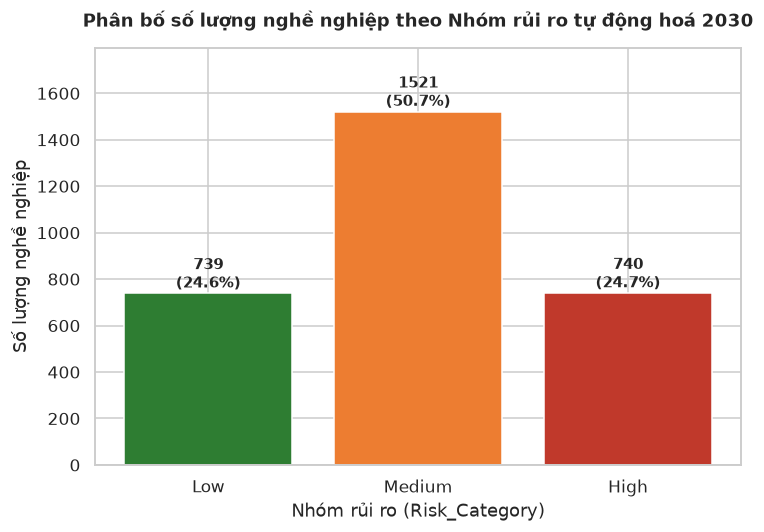

In [12]:
fig, ax = plt.subplots(figsize=(7, 5))
order = df["Risk_Category"].value_counts().reindex(RISK_ORDER)
bars = ax.bar(order.index, order.values, color=[PALETTE_RISK[c] for c in order.index])
for b, v in zip(bars, order.values):
    ax.text(b.get_x() + b.get_width() / 2, v + 25, f"{v}\n({v/len(df)*100:.1f}%)",
            ha="center", fontsize=10, fontweight="bold")
ax.set_ylim(0, order.values.max() * 1.18)
ax.set_title("Phân bố số lượng nghề nghiệp theo Nhóm rủi ro tự động hoá 2030", fontweight="bold", pad=14)
ax.set_xlabel("Nhóm rủi ro (Risk_Category)")
ax.set_ylabel("Số lượng nghề nghiệp")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_risk_category_distribution.png")
plt.show()

**Nhận xét:** Nhóm `Medium` chiếm đa số (50,7%), hai nhóm `Low` và `High` gần như cân bằng (~24,6-24,7%) — cơ cấu này phản ánh cách chia ngưỡng đối xứng của `Automation_Probability_2030` quanh khoảng giữa, không phản ánh phân bố nghề nghiệp thực tế ngoài đời.

### Biểu đồ 2 — Phân bố Xác suất tự động hoá 2030

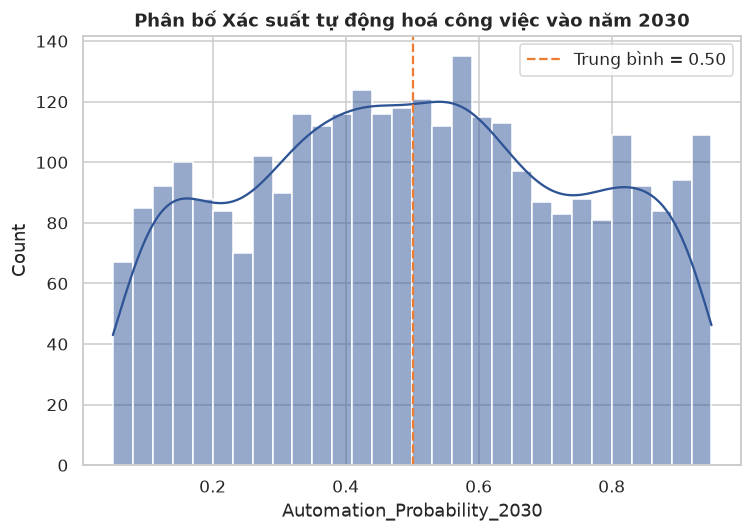

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.histplot(df["Automation_Probability_2030"], bins=30, kde=True, color=HVNH_BLUE, ax=ax)
ax.axvline(df["Automation_Probability_2030"].mean(), color=HVNH_ORANGE, ls="--",
           label=f"Trung bình = {df['Automation_Probability_2030'].mean():.2f}")
ax.set_title("Phân bố Xác suất tự động hoá công việc vào năm 2030", fontweight="bold")
ax.set_xlabel("Automation_Probability_2030")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "02_automation_probability_distribution.png")
plt.show()

**Nhận xét:** Phân bố có 3 "cụm mật độ" rõ rệt tương ứng 3 tầng nghề nghiệp sẽ được làm rõ ở Biểu đồ 8, không phải một phân bố chuẩn (normal) trơn — gợi ý ngay từ EDA rằng biến mục tiêu phụ thuộc vào một yếu tố phân loại (nghề nghiệp) hơn là biến liên tục.

### Biểu đồ 3 — Lương trung bình theo Nhóm rủi ro

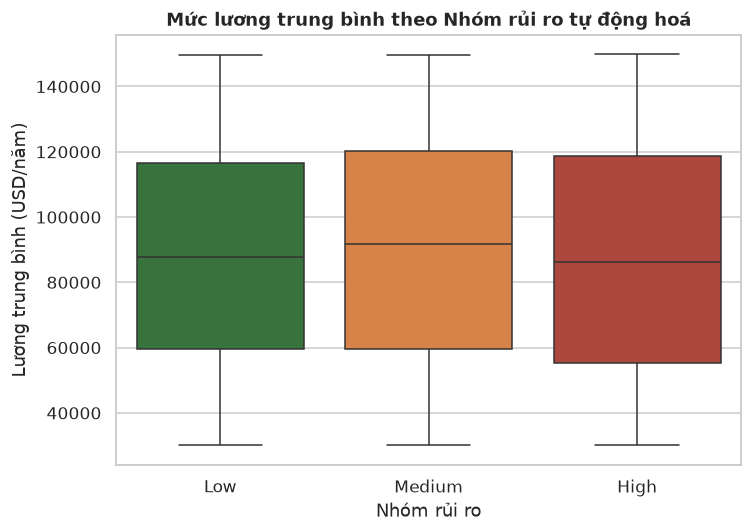

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x="Risk_Category", y="Average_Salary", order=RISK_ORDER, palette=PALETTE_RISK, ax=ax)
ax.set_title("Mức lương trung bình theo Nhóm rủi ro tự động hoá", fontweight="bold")
ax.set_xlabel("Nhóm rủi ro"); ax.set_ylabel("Lương trung bình (USD/năm)")
plt.tight_layout()
plt.savefig(FIG_DIR / "03_salary_by_risk_category.png")
plt.show()

**Nhận xét:** Trung vị và độ trải của lương gần như giống nhau ở cả 3 nhóm rủi ro — mức lương KHÔNG phải là yếu tố phân biệt nhóm rủi ro trong bộ dữ liệu này.

### Biểu đồ 4 — Trình độ học vấn theo Nhóm rủi ro

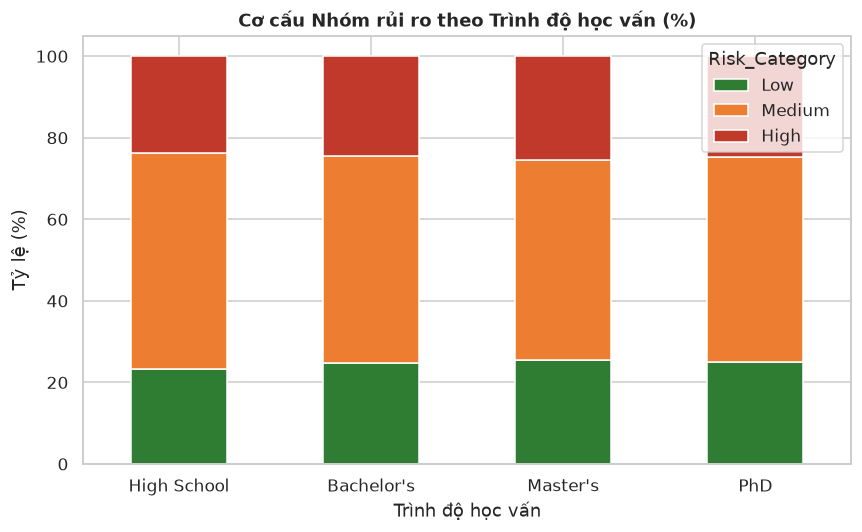

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ct = pd.crosstab(df["Education_Level"], df["Risk_Category"], normalize="index")[RISK_ORDER] * 100
ct = ct.reindex(["High School", "Bachelor's", "Master's", "PhD"])
ct.plot(kind="bar", stacked=True, color=[PALETTE_RISK[c] for c in RISK_ORDER], ax=ax)
ax.set_title("Cơ cấu Nhóm rủi ro theo Trình độ học vấn (%)", fontweight="bold")
ax.set_xlabel("Trình độ học vấn"); ax.set_ylabel("Tỷ lệ (%)")
ax.legend(title="Risk_Category"); plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / "04_education_vs_risk.png")
plt.show()

**Nhận xét:** Cơ cấu rủi ro gần như đồng nhất giữa 4 nhóm học vấn (~25% Low, ~50% Medium, ~25% High mỗi nhóm) — học vấn cũng không phải yếu tố phân biệt, trái với trực giác thông thường rằng trình độ cao hơn thường gắn với công việc ít bị tự động hoá hơn.

### Biểu đồ 5 — Chỉ số Phơi nhiễm AI so với Xác suất tự động hoá

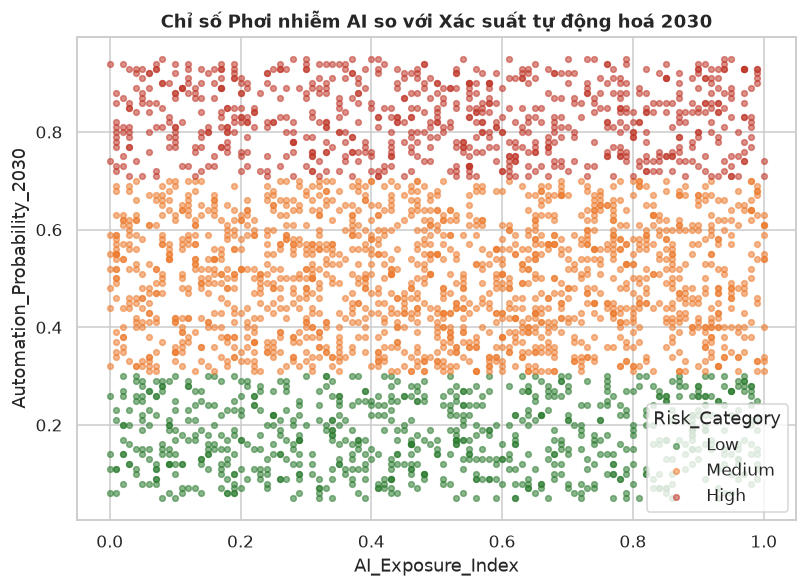

In [16]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for cat in RISK_ORDER:
    sub = df[df["Risk_Category"] == cat]
    ax.scatter(sub["AI_Exposure_Index"], sub["Automation_Probability_2030"],
               s=14, alpha=0.55, color=PALETTE_RISK[cat], label=cat)
ax.set_title("Chỉ số Phơi nhiễm AI so với Xác suất tự động hoá 2030", fontweight="bold")
ax.set_xlabel("AI_Exposure_Index"); ax.set_ylabel("Automation_Probability_2030")
ax.legend(title="Risk_Category")
plt.tight_layout()
plt.savefig(FIG_DIR / "05_ai_exposure_vs_automation.png")
plt.show()

**Nhận xét:** Các điểm phân tán đều theo mọi hướng, không có xu hướng tuyến tính — `AI_Exposure_Index` (một chỉ số tưởng như liên quan trực tiếp đến chủ đề) thực chất KHÔNG tương quan với xác suất tự động hoá trong bộ dữ liệu mô phỏng này.

### Biểu đồ 6 — Ma trận tương quan

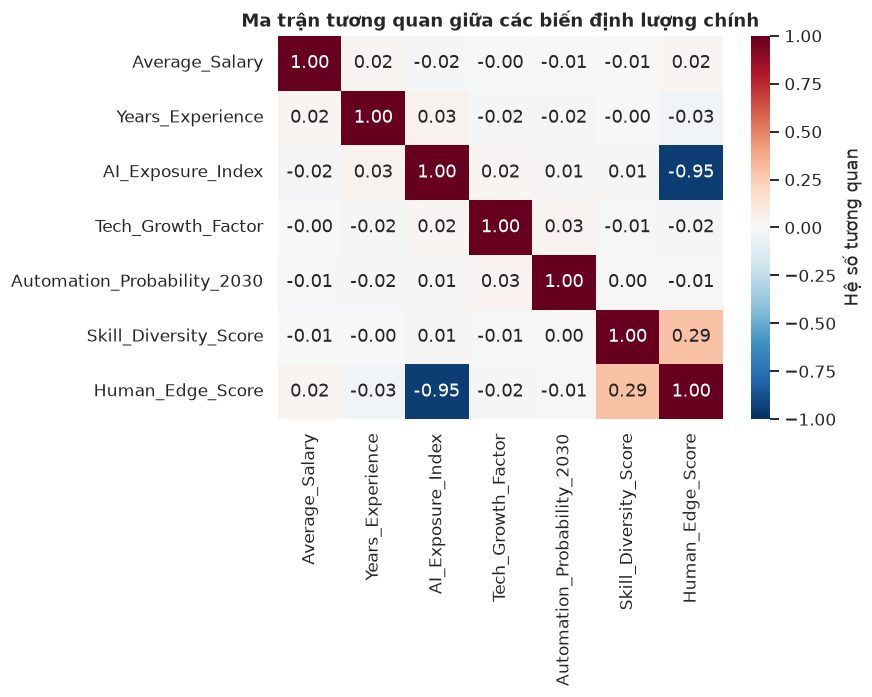

In [17]:
corr_cols = ["Average_Salary", "Years_Experience", "AI_Exposure_Index", "Tech_Growth_Factor",
             "Automation_Probability_2030", "Skill_Diversity_Score", "Human_Edge_Score"]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            ax=ax, cbar_kws={"label": "Hệ số tương quan"})
ax.set_title("Ma trận tương quan giữa các biến định lượng chính", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "06_correlation_heatmap.png")
plt.show()

**Nhận xét:** Toàn bộ hệ số tương quan với `Automation_Probability_2030` đều xấp xỉ 0 (|r| < 0.05) — khẳng định thêm rằng các biến định lượng cấp cá nhân không giải thích được biến mục tiêu; nguyên nhân thực sự sẽ được truy tìm ở Biểu đồ 8.

### Biểu đồ 7 — Kinh nghiệm làm việc và Xác suất tự động hoá

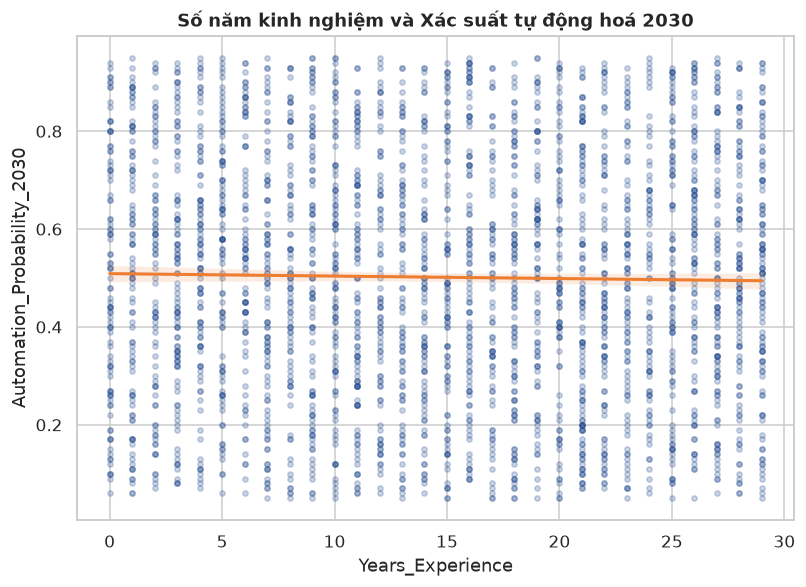

In [18]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.regplot(data=df, x="Years_Experience", y="Automation_Probability_2030",
            scatter_kws={"alpha": 0.25, "s": 12, "color": HVNH_BLUE},
            line_kws={"color": HVNH_ORANGE, "lw": 2}, ax=ax)
ax.set_title("Số năm kinh nghiệm và Xác suất tự động hoá 2030", fontweight="bold")
plt.tight_layout()
plt.savefig(FIG_DIR / "07_experience_vs_automation.png")
plt.show()

**Nhận xét:** Đường hồi quy gần như phẳng (hệ số góc ≈ 0) — số năm kinh nghiệm không làm giảm hay tăng rủi ro tự động hoá trong dữ liệu mô phỏng, khác với kỳ vọng thông thường.

### Biểu đồ 8 — Xác suất tự động hoá theo Nghề nghiệp (bằng chứng then chốt)

Sau khi loại trừ mọi biến định lượng cấp cá nhân, bước cuối cùng là kiểm tra biến định danh
duy nhất còn lại: `Job_Title`.

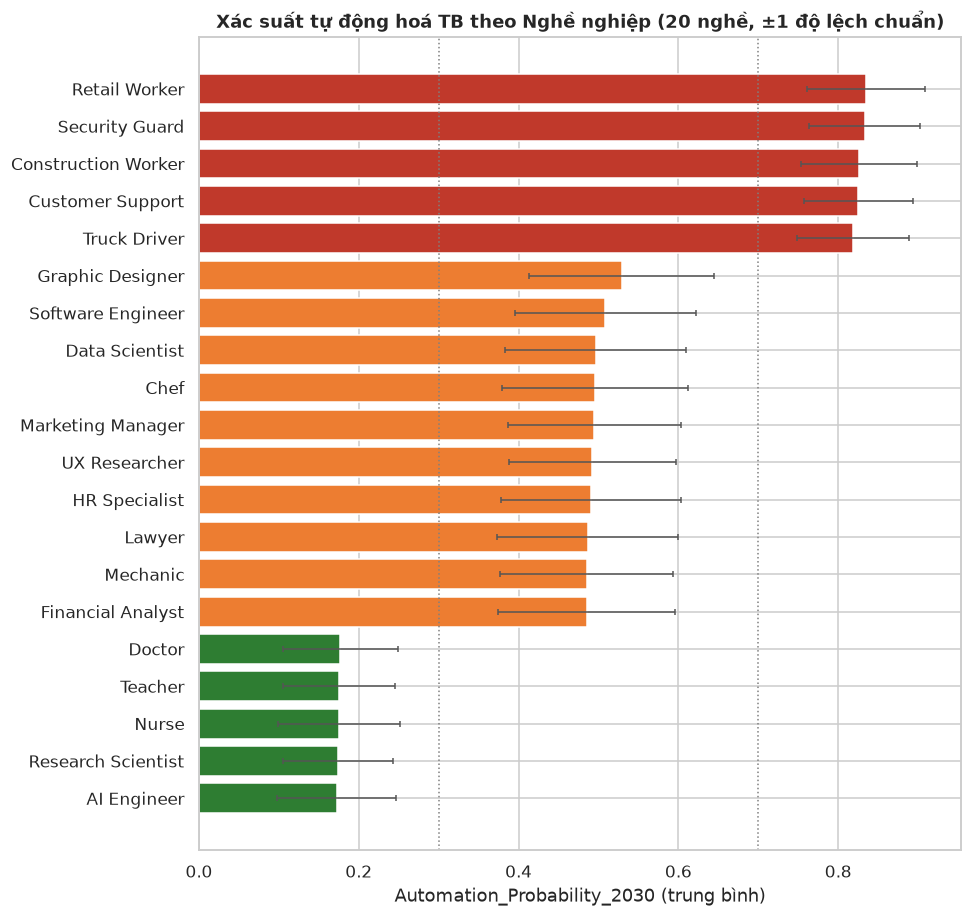

In [19]:
job_stats = df.groupby("Job_Title")["Automation_Probability_2030"].agg(["mean", "std", "count"]).sort_values("mean")

def _tier_color(v):
    if v < 0.30: return PALETTE_RISK["Low"]
    if v > 0.70: return PALETTE_RISK["High"]
    return PALETTE_RISK["Medium"]

colors_tier = [_tier_color(v) for v in job_stats["mean"]]
fig, ax = plt.subplots(figsize=(9, 8.5))
ax.barh(job_stats.index, job_stats["mean"], xerr=job_stats["std"], color=colors_tier,
        error_kw={"ecolor": "#555555", "elinewidth": 1, "capsize": 2})
ax.set_title("Xác suất tự động hoá TB theo Nghề nghiệp (20 nghề, ±1 độ lệch chuẩn)", fontweight="bold")
ax.set_xlabel("Automation_Probability_2030 (trung bình)")
ax.axvline(0.30, color="grey", ls=":", lw=1); ax.axvline(0.70, color="grey", ls=":", lw=1)
plt.tight_layout()
plt.savefig(FIG_DIR / "08_jobtitle_automation_ranked.png")
plt.show()

In [20]:
overall_mean = df["Automation_Probability_2030"].mean()
ss_between = float(((job_stats["mean"] - overall_mean) ** 2 * job_stats["count"]).sum())
ss_total = float(((df["Automation_Probability_2030"] - overall_mean) ** 2).sum())
eta_squared_job = ss_between / ss_total
print(f"Eta^2 (Job_Title -> Automation_Probability_2030) = {eta_squared_job:.4f}")
print(f"=> Job_Title giải thích {eta_squared_job*100:.1f}% phương sai của biến mục tiêu.")

Eta^2 (Job_Title -> Automation_Probability_2030) = 0.8570
=> Job_Title giải thích 85.7% phương sai của biến mục tiêu.


**Nhận xét (phát hiện quan trọng nhất của notebook):** 20 nghề tách thành **3 tầng rõ rệt**:
- **Tầng thấp (~0,17-0,18):** AI Engineer, Research Scientist, Nurse, Teacher, Doctor — nghề đòi hỏi
  phán đoán chuyên môn sâu, chăm sóc/tương tác con người cao.
- **Tầng trung bình (~0,48-0,53):** 10 nghề chuyên môn/văn phòng còn lại.
- **Tầng cao (~0,82-0,83):** Truck Driver, Customer Support, Construction Worker, Security Guard,
  Retail Worker — nghề có tỷ trọng tác vụ lặp lại/thủ tục cao.

`Job_Title` giải thích tới **~86% phương sai** của xác suất tự động hoá — vượt trội hoàn toàn so
với mọi biến cá nhân đã kiểm tra ở Biểu đồ 2-7. Kết luận sơ bộ này phù hợp với **lý thuyết tiếp
cận theo tác vụ (task-based approach)** của Autor, Levy & Murnane (2003) và nghiên cứu thực nghiệm
của Frey & Osborne (2013) — rủi ro tự động hoá được quyết định bởi **bản chất công việc/nghề
nghiệp**, không phải đặc điểm cá nhân của người đang làm nghề đó. Phát hiện này sẽ dẫn dắt toàn bộ
chiến lược mô hình hoá ở Notebook 2: bắt buộc phải đưa `Job_Title` vào tập đặc trưng.

## 4. Tóm tắt Notebook 1 & bước tiếp theo

1. Dữ liệu sạch, không thiếu/trùng/ngoại lai — 3.000 dòng x 25 cột sau feature engineering,
   đã lưu vào `AI_ViecLam2030_Cleaned.csv`.
2. Phát hiện rò rỉ dữ liệu: `Risk_Category` = hàm ngưỡng của `Automation_Probability_2030`
   → loại biến này khỏi tập đặc trưng phân loại.
3. Phát hiện cấu trúc dữ liệu cốt lõi: rủi ro tự động hoá được quyết định ở **cấp độ nghề
   nghiệp** (eta² ≈ 0,86), không phải ở cấp độ đặc điểm cá nhân người lao động.

→ Tiếp tục ở **Notebook 2 — `AI_ViecLam2030_Data_Processing_and_Mining_DoVanDat.ipynb`**:
phân cụm hồ sơ kỹ năng, mô hình phân loại `Risk_Category` và mô hình hồi quy
`Automation_Probability_2030` có đưa `Job_Title` vào tập đặc trưng.